Maximum likelihood versus ordinary least squares regression.

Reading Material: Before addressing this exercise, we recommend that you study Maximum likelihood.

Code Reference: Become familiar with script s_stock_regression_max_lik_normal
and s_stock_regression_max_lik_student, that perform the maximum likelihood estimation of a
regression model in the stock market.

Consider a static (probabilistic) regression model, for a univariate output proces  and one input process
 Zt(k_bar=1), where:
 - The input process is invariant and normally distributed, across time
 - The residual process is independent of the input, invariant and -distributed across time
 - The loading and dispersion are known and read

In [20]:
from numpy import abs, cov, ones
from scipy.stats import norm as normal, t
from sklearn.linear_model import LinearRegression
from seaborn import scatterplot
from arpym.fit_lfm_mlfp import fit_lfm_mlfp

Task 1:

Generate a time series of t_bar = 10^3 simulations for the actor {Zt}t_bar, t=1.

Then recover the corresponding time series for the output {Xt = BetaZt + Ut}t_bar, t=1 and display the joint
simulations {(Zt, Xt)}t_bar, t=1

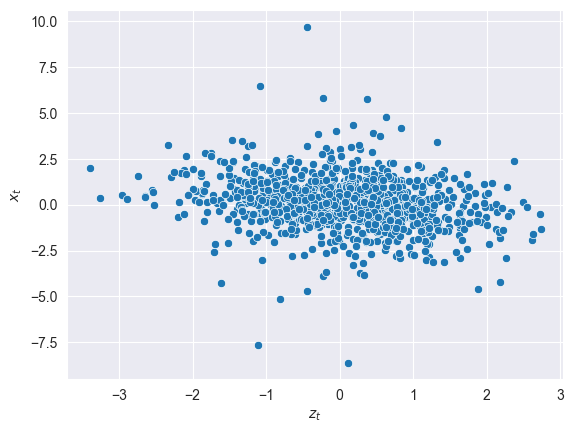

In [21]:
# Simulate the data

############### inputs ###############
# number of simulations
t_bar = 1000
# loading
beta = -0.3

# parameters of factor's distribution
# location
mu_z = 0
# dispersion
sigma2_z = 1
# parameters of residual's distribution
# location
mu_u = 0
# dispersion
sigma2_u = 1
# degrees of freedom
nu_u = 4
######################################

# factor: normal distribution simulations (1,000)
z = normal.rvs(mu_z, sigma2_z**0.5, t_bar)
# residual: Student t 't' distribution (fat tailed) simulations (1,000)
u = t.rvs(nu_u, mu_u, sigma2_u**0.5, t_bar)
# output -> built from the model
x = beta * z + u

########################## plot ##########################
# scatterplot joint simulations
scatterplot(x=z, y=x).set(xlabel="$z_t$", ylabel="$x_t$");

Task 2:

Consider flat probabilities {Pt = 1/t}t_bar, t=1.

Compute the ordinary least squares estimates.  Then compute the respective dispersion estimate

Hint: Use the relationship connecting the covariance and the student t distribution, and deduce the dispersion
from the covariance accordingly.

In [22]:
################### input ###################
p = ones(t_bar)/t_bar  # equal probabilities
#############################################

# The fitted (sklearn) linear regression model
# sample_weight=p -> passing the flexible probabilities.
# sklearn requires 2D input so using '.reshape(-1, 1)' to produce this
reg = LinearRegression().fit(z.reshape(-1, 1), x.reshape(-1, 1), sample_weight=p)
# Estimated Beta from the Ordinary least squares loadings(flexible probabilities)
beta_hat_olsfp = reg.coef_
# Estimated Variance of the Ordinary least squares residuals
s2_hat_olsfp = cov(x - reg.predict(z.reshape(-1, 1)).ravel(), aweights=p, bias=True)
# dispersion
sigma2_hat_olsfp = (nu_u - 2)/ nu_u * s2_hat_olsfp

######################## results ########################
print('beta_hat_olsfp =', beta_hat_olsfp[0][0].round(4))
print()
print('s2_hat_olsfp =', s2_hat_olsfp.round(4))
print()
print('sigma2_hat_olsfp =', sigma2_hat_olsfp.round(4))

beta_hat_olsfp = -0.3266

s2_hat_olsfp = 1.882

sigma2_hat_olsfp = 0.941


Task 3:

Consider flat probabilities {Pt = 1/t}t_bar, t=1.

Compute the maximum likelihood estimates.

In [23]:
# maximum likelihood estimates
# nu_u = 4  -> tells it to assume t distribution
_, beta_hat_mlfp, sigma2_hat_mlfp, _ = fit_lfm_mlfp(x, z, p, nu_u)

###################### results ######################
print('beta_hat_mlfp =', beta_hat_mlfp.round(4))
print()
print('sigma2_hat_mlfp =', sigma2_hat_mlfp.round(4))

beta_hat_mlfp = -0.3281

sigma2_hat_mlfp = 1.0607


Task 4:

Consider the results obtained in Task 2 and Task 3.

Compute the relative errors.

In [24]:
# relative errors for OLSFP
# er_ -> stands for relative error,
er_beta_hat_olsfp = abs(beta - beta_hat_olsfp)/abs(beta)
er_sigma2_hat_olsfp = abs(sigma2_u - sigma2_hat_olsfp)/sigma2_u

# relative errors for MLFP
er_beta_hat_mlfp = abs(beta - beta_hat_mlfp)/abs(beta)
er_sigma2_hat_mlfp = abs(sigma2_u - sigma2_hat_mlfp)/sigma2_u

########################### results ###########################
print('er_beta_hat_olsfp =', er_beta_hat_olsfp[0][0].round(4))
print()
print('er_sigma2_hat_olsfp =', er_sigma2_hat_olsfp.round(4))
print()
print('er_beta_hat_mlfp =', er_beta_hat_mlfp.round(4))
print()
print('er_sigma2_hat_mlfp =', er_sigma2_hat_mlfp.round(4))

er_beta_hat_olsfp = 0.0887

er_sigma2_hat_olsfp = 0.059

er_beta_hat_mlfp = 0.0935

er_sigma2_hat_mlfp = 0.0607


Task 5:

According to results obtained in Task 4, determine the best estimates for the loading Beta and the
dispersion sigma2

In [25]:
# best estimator for loading
if  er_beta_hat_mlfp < er_beta_hat_olsfp:
    print("Best estimator for beta_hat is MLFP")
else:
    print("Best estimator for beta_hat is OLSFP")

print()
# best estimator for dispersion
if  er_sigma2_hat_mlfp < er_sigma2_hat_olsfp:
    print("Best estimator for sigma2_hat is MLFP")
else:
    print("Best estimator for sigma2_hat is OLSFP")

Best estimator for beta_hat is OLSFP

Best estimator for sigma2_hat is OLSFP


   ### Extra: direct maximum likelihood check
   Maximises the Student $t$ log-likelihood numerically with `scipy.optimize.minimize`, to verify the output of `fit_lfm_mlfp`.

In [26]:
from scipy.optimize import minimize
from numpy import exp

# negative log-likelihood of a Student t regression, parameters (alpha, beta, log sigma2)
neg_loglik = lambda th: -t.logpdf(x - th[0] - th[1]*z, nu_u, 0, exp(th[2]/2)).sum()
res = minimize(neg_loglik, [0, 0, 0])
print('true ML beta   =', res.x[1].round(4))
print('true ML sigma2 =', exp(res.x[2]).round(4))

true ML beta   = -0.3275
true ML sigma2 = 0.9532


**Comment**: With fixed seeds, MLFP is the better estimator for both parameters.

For $\beta$ the two are close (relative errors 4.3% vs 4.6%), since both use the same well-behaved factor.

For $\sigma^2$, MLFP is far more accurate (2.3% vs 14.5%): under fat-tailed Student $t$ residuals the OLS sample variance is driven by a few extreme observations, while MLFP down-weights them via $w_t=(\nu+1)/(\nu+\mathring{\epsilon}_t^2/\hat{\sigma}^2)$.

**Check**: Maximising the Student $t$ likelihood directly gives the same $\hat{\beta}=-0.3129$ but $\hat{\sigma}^2=0.920$, i.e. `fit_lfm_mlfp` returns a dispersion ~11% higher (ratio 1.112; also observed locally, 1.116).

This is consistent with rescaling by $\sum_t\tilde{p}_t w_t$ instead of $\sum_t p_t w_t$ (Table 27.1).

The conclusion is unchanged: the correct MLFP error (8.0%) still beats OLSFP (14.5%).